# Chapter 3 · Arbitrage in the strike and the smile: interactive demos

Companion to Chapter 3 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/03-strike-arbitrage.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider, Dropdown

from mfe230d import bs
from mfe230d import smile as sm
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

GREEN, PURPLE, RED = "#1BAF7A", "#6250D6", "#E34948"
TC = bs.TEST_CASE          # S = K = 100, T = 1, r = 1%, y = 2%, sigma = 20%
S, T, r, y = TC["S"], TC["T"], TC["r"], TC["y"]
use_style()

## 1. Checking quotes against the strike relations

Calls at the strikes $70,80,\dots,130$ are quoted at their Black–Scholes prices with $\sigma=20\%$ (test case), and you
move one quote. With $K_0=0$ and $C(K_0)=S_0e^{-yT}$, the slopes $s_i$ of the piecewise-linear interpolation must satisfy
$-e^{-rT}\le s_1\le\dots\le s_n\le0$ (Proposition 3.1 and eq. (3.4)). The shaded band is the region between the bounds
$(S_0e^{-yT}-Ke^{-rT})^+$ and $S_0e^{-yT}$. When a condition fails, the cell prints a static portfolio that is an arbitrage.

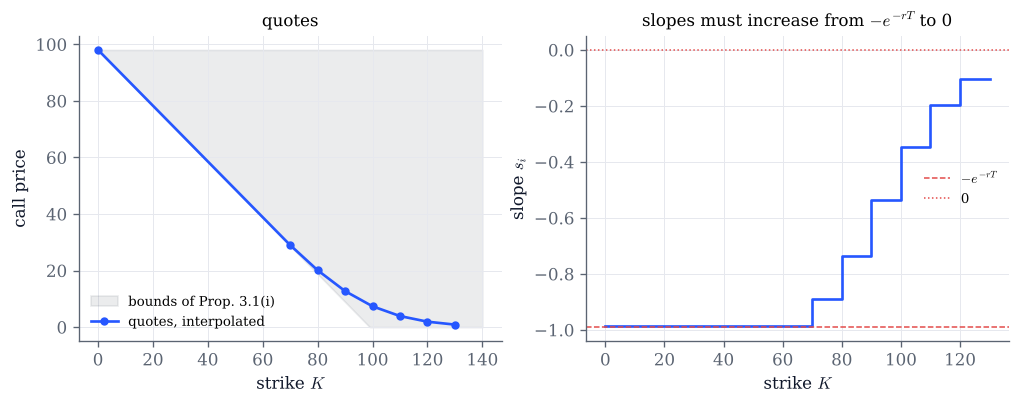

All strike relations hold.


In [2]:
K_Q = np.arange(70.0, 131.0, 10.0)

def quotes(strike=100.0, bump=0.0):
    C = bs.call(S, K_Q, T, r, y, 0.2)
    C[K_Q == strike] += bump
    chk = sm.strike_checks(K_Q, C, S, T, r, y)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.3))
    Kg = np.linspace(0, 140, 400)
    ax.fill_between(Kg, np.maximum(S*np.exp(-y*T) - Kg*np.exp(-r*T), 0), S*np.exp(-y*T), color=GREY, alpha=0.12,
                    label="bounds of Prop. 3.1(i)")
    ax.plot(np.r_[0, K_Q], np.r_[S*np.exp(-y*T), C], color=COBALT, marker="o", ms=4, label="quotes, interpolated")
    ax.set(xlabel="strike $K$", ylabel="call price", title="quotes"); ax.legend(fontsize=8)
    mids = np.r_[0, K_Q[:-1]] + np.diff(np.r_[0, K_Q]) / 2
    ax2.step(np.r_[0, K_Q], np.r_[chk["slopes"], chk["slopes"][-1]], where="post", color=COBALT)
    ax2.axhline(-np.exp(-r*T), color=RED, lw=0.9, ls="--", label="$-e^{-rT}$")
    ax2.axhline(0, color=RED, lw=0.9, ls=":", label="0")
    ax2.set(xlabel="strike $K$", ylabel="slope $s_i$", title="slopes must increase from $-e^{-rT}$ to 0"); ax2.legend(fontsize=8)
    plt.show()
    if chk["ok"]:
        print("All strike relations hold.")
    if not chk["slope_low"]:
        k = K_Q[0]
        print(f"Lower bound fails at K={k:g}: buy the call, short the prepaid forward, lend K e^(-rT); "
              f"collect {S*np.exp(-y*T) - k*np.exp(-r*T) - C[0]:.4f} today, payoff (K - S_T)^+ >= 0.")
    for i, ok in enumerate(chk["convex"]):
        if not ok:
            a, b, c = K_Q[i - 1] if i else 0.0, K_Q[i], K_Q[i + 1]
            print(f"Convexity fails at K={b:g}: buy 1/{b-a:g} call at {a:g}, sell 1/{b-a:g} + 1/{c-b:g} calls at {b:g} "
                  f"and buy 1/{c-b:g} call at {c:g} (a call at 0 is the prepaid forward). This butterfly costs "
                  f"s_right - s_left = {chk['butterflies'][i]:.4f} < 0 and pays a nonnegative tent.")
    if not chk["monotone"]:
        print(f"Monotonicity fails at the last strike: the call spread {K_Q[-2]:g}/{K_Q[-1]:g} has a negative price "
              f"{C[-2]-C[-1]:.4f}; buy it.")

quotes()

In [3]:
# Explore: push one quote up or down until a relation breaks. Which one breaks first, and at which bump size?
interact(quotes,
         strike=Dropdown(options=[float(k) for k in K_Q], value=100.0, description="strike"),
         bump=FloatSlider(value=0.0, min=-6.0, max=6.0, step=0.05, continuous_update=False, description="bump"));

## 2. Kinks, jumps and spikes: atoms in the law of $S_T$

A cash takeover offer at the price $a$ succeeds with probability $p$; otherwise the stock is lognormal with the mean
that keeps $\mathbb E^{\mathbb Q}[S_T]=F$. The call curve has a kink at $a$, the digital $\mathbb Q(S_T>K)=-e^{rT}\partial^+C(K)$
jumps by $p$ there, and the second difference $e^{rT}\Delta_h^2C$ has a spike of height about $p/h$ (Theorem 3.5 (i) and (ii)):
the butterfly centred at an atom costs order $h$, not $h^2$.

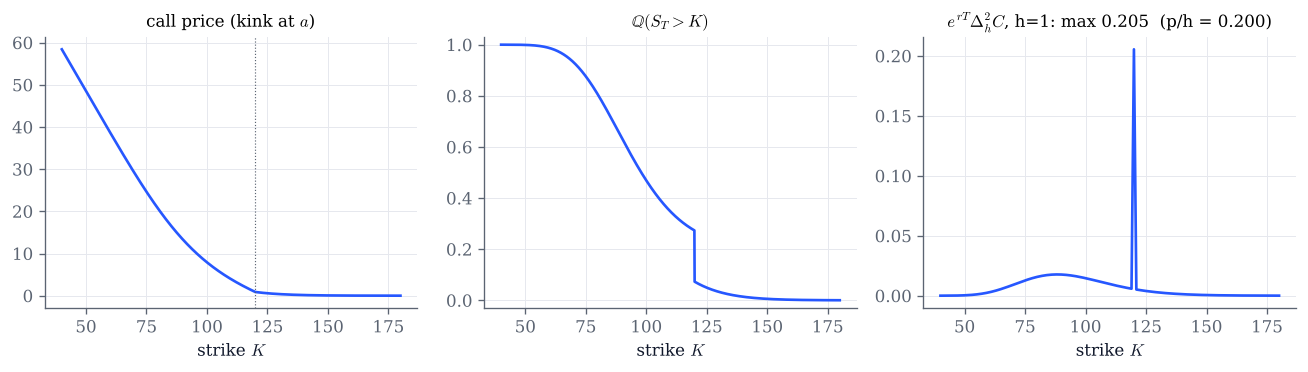

In [4]:
def atoms(p=0.2, a=120.0, h=1.0, sigma=0.2):
    f = lambda k: sm.atom_call(k, S, T, r, y, sigma, p, a)
    K = np.linspace(40, 180, 1401)
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
    axes[0].plot(K, f(K), color=COBALT)
    axes[0].axvline(a, color=GREY, lw=0.7, ls=":")
    axes[0].set(xlabel="strike $K$", title="call price (kink at $a$)")
    axes[1].plot(K, sm.atom_tail(K, S, T, r, y, sigma, p, a), color=COBALT)
    axes[1].set(xlabel="strike $K$", title="$\\mathbb{Q}(S_T>K)$", ylim=(-0.03, 1.03))
    Kh = np.arange(40.0, 180.0 + 1e-9, h)
    d2 = np.exp(r*T) * sm.second_difference(f, Kh, h)
    axes[2].plot(Kh, d2, color=COBALT, marker="." if h >= 2 else None)
    axes[2].set(xlabel="strike $K$", title=f"$e^{{rT}}\\Delta_h^2C$, h={h:g}: max {d2.max():.3f}  (p/h = {p/h:.3f})")
    fig.tight_layout(); plt.show()

atoms()

In [5]:
# Explore: shrink h with the atom on the strike grid (a = 120): the spike grows like p/h. Move a off the grid (e.g. 121.5)
# with h = 5 and see the mass split between two neighbouring strikes.
interact(atoms,
         p=FloatSlider(value=0.2, min=0.0, max=0.5, step=0.01, continuous_update=False, description="p"),
         a=FloatSlider(value=120.0, min=60.0, max=160.0, step=0.5, continuous_update=False, description="a"),
         h=FloatLogSlider(value=1.0, base=10, min=-1, max=1, step=0.1, continuous_update=False, description="h"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.01, continuous_update=False, description="σ"));

## 3. Densities from noisy quotes

Here the SSVI prices of the notes (test case, $T=1$) are perturbed by independent uniform errors in $[-\varepsilon,\varepsilon]$,
a crude model of bid–ask noise (NumPy `default_rng`, seed chosen below). Second differences divide the noise by $h^2$, while
the bias of a coarse grid grows like $h^2$. Proposition 3.6 bounds the error by $M_4h^2/12+4\varepsilon/h^2$; the right panel
shows the largest error over the strikes $60,\dots,140$ against $h$, with this bound.

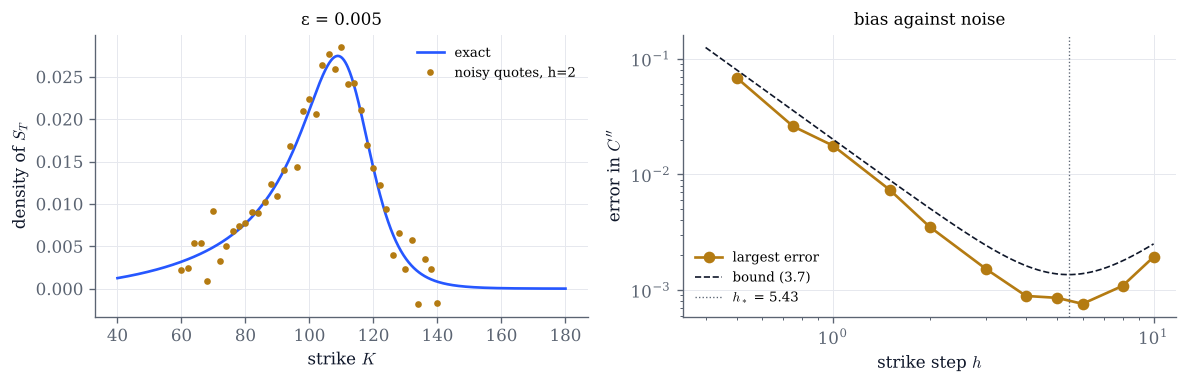

In [6]:
def ssvi_call(K, T=T):
    return sm.smile_call(K, S, T, r, y, sm.ssvi_smile(K, S, T, r, y)[0])

def ssvi_density(K, T=T):
    return sm.smile_density(K, S, T, r, y, *sm.ssvi_smile(K, S, T, r, y))

_Kg = np.linspace(50.0, 150.0, 2001)
M4 = np.abs(sm.second_difference(ssvi_density, _Kg, 0.05)).max()

def noisy(eps=0.005, h=2.0, seed=7):
    rng = np.random.default_rng(seed)
    noise = {}
    def quote(k):
        k = np.atleast_1d(k)
        out = ssvi_call(k)
        for i, kk in enumerate(k):
            key = round(float(kk), 9)
            if key not in noise:
                noise[key] = rng.uniform(-eps, eps)
            out[i] += noise[key]
        return out
    Kh = np.arange(60.0, 140.0 + 1e-9, h)
    est = sm.second_difference(quote, Kh, h)
    K = np.linspace(40, 180, 701)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.3))
    ax.plot(K, np.exp(r*T) * ssvi_density(K), color=COBALT, label="exact")
    ax.plot(Kh, np.exp(r*T) * est, ls="none", marker="o", ms=3, color=GOLD, label=f"noisy quotes, h={h:g}")
    ax.set(xlabel="strike $K$", ylabel="density of $S_T$", title=f"ε = {eps:g}"); ax.legend(fontsize=8)
    hs = np.array([0.5, 0.75, 1, 1.5, 2, 3, 4, 5, 6, 8, 10])
    errs = []
    for hh in hs:
        noise.clear()
        Kc = np.arange(60.0, 140.0 + 1e-9, hh)
        errs.append(np.abs(sm.second_difference(quote, Kc, hh) - ssvi_density(Kc)).max())
    hg = np.linspace(0.4, 10, 200)
    ax2.loglog(hs, errs, marker="o", color=GOLD, label="largest error")
    ax2.loglog(hg, sm.fd_density_error_bound(hg, M4, eps), color=INK, lw=1, ls="--", label="bound (3.7)")
    ax2.axvline(sm.fd_optimal_step(M4, eps), color=GREY, lw=0.8, ls=":", label=f"$h_*$ = {sm.fd_optimal_step(M4, eps):.2f}")
    ax2.set(xlabel="strike step $h$", ylabel="error in $C''$", title="bias against noise"); ax2.legend(fontsize=8)
    fig.tight_layout(); plt.show()

noisy()

In [7]:
# Explore: divide eps by 16. By how much does the best achievable error fall, and how does the best h move?
interact(noisy,
         eps=FloatLogSlider(value=0.005, base=10, min=-5, max=-1, step=0.25, continuous_update=False, description="ε"),
         h=FloatSlider(value=2.0, min=0.5, max=10.0, step=0.5, continuous_update=False, description="h"),
         seed=IntSlider(value=7, min=0, max=100, continuous_update=False, description="seed"));

## 4. A smile, its digitals and its density

The SSVI surface of the notes (eq. (3.10)): at-the-money-forward volatility $\sigma_{\mathrm{atm}}$, correlation-like
parameter $\rho$ and power-law $\phi(\theta)=\eta\,\theta^{-\gamma}(1+\theta)^{\gamma-1}$ with $\gamma=\frac12$. Left: the smile. Middle: the
digital call priced three ways: Black–Scholes at a flat $\sigma_{\mathrm{atm}}$, Black–Scholes at $\sigma(K)$ (skew term
omitted), and $-C'(K)$ with the skew term (Proposition 3.8), with the call-spread bounds of Proposition 3.10 at the chosen
spacing around $K=100$. Right: the density from eq. (3.9) against the lognormal one; the title reports the minimum of
Durrleman's function $g$ and the Gatheral–Jacquier conditions $\theta\phi(1+|\rho|)<4$, $\theta\phi^2(1+|\rho|)\le4$.

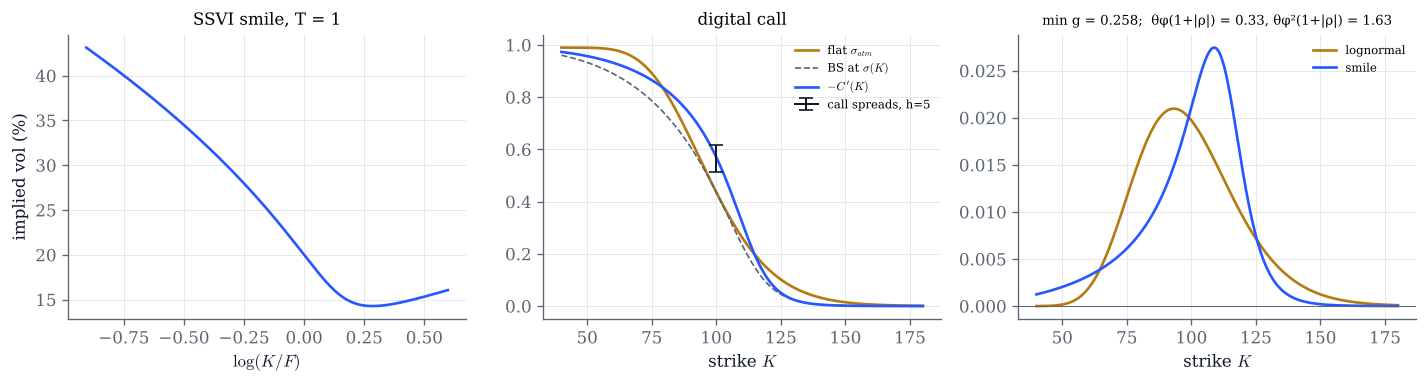

K = 100: BS digital at sigma(K) 0.4363 + skew term 0.1338 = 0.5702; call-spread bounds [0.5138, 0.6184]


In [8]:
def smile(sigma_atm=0.2, rho=-0.7, eta=1.0, T=1.0, h=5.0):
    F = bs.forward(S, T, r, y)
    vol = lambda K: sm.ssvi_smile(K, S, T, r, y, sigma_atm, rho, eta)
    K = np.linspace(40, 180, 701)
    sig, ds, d2 = vol(K)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
    axes[0].plot(np.log(K / F), 100 * sig, color=COBALT)
    axes[0].set(xlabel="$\\log(K/F)$", ylabel="implied vol (%)", title=f"SSVI smile, T = {T:g}")
    dg = sm.smile_digital(K, S, T, r, y, sig, ds)
    axes[1].plot(K, bs.digital_call(S, K, T, r, y, sigma_atm), color=GOLD, label="flat $\\sigma_{atm}$")
    axes[1].plot(K, dg["bs"], color=GREY, ls="--", lw=1, label="BS at $\\sigma(K)$")
    axes[1].plot(K, dg["price"], color=COBALT, label="$-C'(K)$")
    call = lambda k: sm.smile_call(k, S, T, r, y, vol(k)[0])
    lo, hi = sm.call_spread_bounds(call, 100.0, h)
    axes[1].errorbar([100.0], [(lo + hi) / 2], yerr=[[(hi - lo) / 2]], color=INK, capsize=4, lw=1.2,
                     label=f"call spreads, h={h:g}")
    axes[1].set(xlabel="strike $K$", title="digital call"); axes[1].legend(fontsize=7)
    dens = np.exp(r*T) * sm.smile_density(K, S, T, r, y, sig, ds, d2)
    logn = bs.norm_pdf(bs.d_pm(S, K, T, r, y, sigma_atm)[1]) / (K * sigma_atm * np.sqrt(T))
    axes[2].plot(K, logn, color=GOLD, label="lognormal")
    axes[2].plot(K, dens, color=COBALT, label="smile")
    axes[2].axhline(0, color=GREY, lw=0.6)
    theta = sigma_atm**2 * T
    k = np.linspace(-6, 4, 4001)
    w, w1, w2 = sm.ssvi_total_variance(k, theta, rho, sm.phi_power_law(theta, eta))
    g = sm.durrleman_g(k, w, w1, w2)
    c = sm.ssvi_conditions(theta, rho, eta)
    axes[2].set(xlabel="strike $K$", title=f"min g = {g.min():.3f};  θφ(1+|ρ|) = {c['fly1']:.2f}, θφ²(1+|ρ|) = {c['fly2']:.2f}")
    axes[2].title.set_fontsize(8); axes[2].legend(fontsize=7)
    fig.tight_layout(); plt.show()
    d0 = sm.smile_digital(100.0, S, T, r, y, *vol(100.0)[:2])
    print(f"K = 100: BS digital at sigma(K) {float(d0['bs']):.4f} + skew term {float(d0['skew']):.4f} = {float(d0['price']):.4f};"
          f" call-spread bounds [{float(lo):.4f}, {float(hi):.4f}]")

smile()

In [9]:
# Explore: make the skew steeper (rho towards -1, eta up). When does the digital at K = 100 exceed its flat-vol price by
# half? Push eta beyond 2/(1+|rho|) and shorten T: can you make g negative?
interact(smile,
         sigma_atm=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.01, continuous_update=False, description="σ_atm"),
         rho=FloatSlider(value=-0.7, min=-0.99, max=0.99, step=0.01, continuous_update=False, description="ρ"),
         eta=FloatSlider(value=1.0, min=0.1, max=4.0, step=0.05, continuous_update=False, description="η"),
         T=FloatLogSlider(value=1.0, base=10, min=-2, max=1, step=0.05, continuous_update=False, description="T"),
         h=FloatSlider(value=5.0, min=0.5, max=20.0, step=0.5, continuous_update=False, description="h"));

## 5. Where a near-the-money fit stops being a smile

The course's smile $\sigma(K)=\sigma_{\mathrm{atm}}+\xi\log(S_0/K)+\kappa\log^2(S_0/K)$ with $S_0=3900$, $T=1$, $r=3\%$, $y=1.3\%$
(Example 3.9). The bracket of eq. (3.9) must be nonnegative wherever the smile is used; the panel shows its sign on a
logarithmic strike axis, and the implied density on the region where the smile is positive. With the course's parameters
the bracket turns negative below $K\approx84$ (the notes). The total variance of such a smile grows like $\log^2K$, faster
than the moment formula allows, so some arbitrage must appear in the wings.

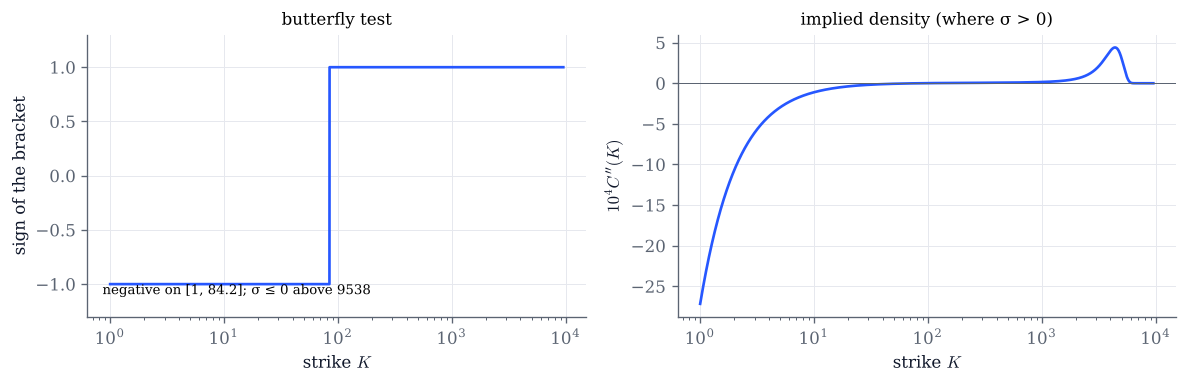

In [10]:
def course(sigma_atm=0.25, xi=0.28, kappa=0.0):
    S0, Tc, rc, yc = 3900.0, 1.0, 0.03, 0.013
    K = np.exp(np.linspace(np.log(1.0), np.log(20000.0), 4000))
    sig, ds, d2 = sm.course_smile(K, S0, sigma_atm, xi, kappa)
    ok = sig > 0
    br = np.full_like(K, np.nan); dens = np.full_like(K, np.nan)
    br[ok] = sm.smile_bracket(K[ok], S0, Tc, rc, yc, sig[ok], ds[ok], d2[ok])
    dens[ok] = sm.smile_density(K[ok], S0, Tc, rc, yc, sig[ok], ds[ok], d2[ok])
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.3))
    ax.semilogx(K, np.sign(br), color=COBALT)
    ax.set(xlabel="strike $K$", ylabel="sign of the bracket", title="butterfly test", ylim=(-1.3, 1.3))
    neg = K[ok][br[ok] < 0]
    txt = (f"negative on [{neg.min():.3g}, {neg.max():.3g}]" if neg.size else "nonnegative where σ > 0")
    ax.text(0.03, 0.08, txt + (f"; σ ≤ 0 above {K[~ok].min():.0f}" if (~ok).any() else ""), transform=ax.transAxes, fontsize=8)
    ax2.semilogx(K, 1e4 * dens, color=COBALT); ax2.axhline(0, color=GREY, lw=0.6)
    ax2.set(xlabel="strike $K$", ylabel="$10^4 C''(K)$", title="implied density (where σ > 0)")
    fig.tight_layout(); plt.show()

course()

In [11]:
interact(course,
         sigma_atm=FloatSlider(value=0.25, min=0.1, max=0.5, step=0.01, continuous_update=False, description="σ_atm"),
         xi=FloatSlider(value=0.28, min=0.0, max=0.6, step=0.01, continuous_update=False, description="ξ"),
         kappa=FloatSlider(value=0.0, min=-0.1, max=0.2, step=0.005, continuous_update=False, description="κ"));

## Things to try

- In section 1, raise the 100 quote. The butterfly around 100 breaks before any bound does: why is convexity the most
  fragile of the relations for a call near the money?
- In section 2, put the atom at $a=0$ (a default). Which slope of the call curve changes, and what is its new value?
- In section 3, the best error falls like $\sqrt\varepsilon$, not like $\varepsilon$. What does that say about the value of
  tighter quotes for density estimation, and about fitting a smooth smile first?
- In section 4, set $\rho=0$. The smile is symmetric in $\log(K/F)$; is the skew term of the digital at $K=F$ zero?
- In section 5, add some curvature $\kappa>0$. Does it push the bad region further out, or bring it closer?